# 02 · MapBiomas Perú — referencia temática y máscara de pastizal

**Qué hace este notebook:** describe de qué está hecha la provincia de Cusco según MapBiomas Perú
Colección 4, construye la **máscara de la clase objetivo** (formación herbácea) y calcula los
**indicadores de referencia** contra los que se contrastará el resultado propio.

**Qué NO hace:** no detecta cambios ni valida nada. MapBiomas aquí es una fuente de contexto y de
delimitación, no de verdad de campo. La razón está en la sección 2.

**Qué entrega al resto del flujo:**

| Salida | La consume |
|---|---|
| Máscara de pastizal (clase 12) | Pasos 4 a 8: define dónde se mide degradación |
| Estratos de exclusión (bofedales, glaciar, agua, roca) | Paso 8: píxeles que no entran al indicador |
| Tabla de áreas por clase y año | `docs/01_datos_fuentes.md` y el informe |
| Matriz de transiciones | Paso 8: contraste con el indicador propio |
| Indicadores de bosque | Entregable secundario, con su limitación declarada |

---

## Por qué este notebook se reescribió (2026-10-22)

La versión anterior (`04_catalogo_indicadores.ipynb`) se hizo cuando el proyecto medía pérdida de
bosque. Tenía tres problemas que este notebook corrige:

1. **Arrancaba en 2010.** Herencia de cuando el periodo eran 15 años y MapBiomas era la serie
   principal: como tiene bandas desde 1985, empezar en 2010 salía gratis. Pero Landsat 8 empieza en
   2013, así que los años 2010–2012 no se pueden comparar contra nada propio.
2. **Agrupaba las clases con criterio propio.** La celda decía "Grupos propuestos", y en efecto lo
   eran: `{'bosque': [3,4,5,6], 'pastos': [12,15], 'urbano': [24], 'agua': [31,33]}`. Solo el primero
   coincide con la jerarquía oficial de MapBiomas; los demás son recortes.
3. **Metía las clases 12 y 15 en el mismo saco.** Es el error de fondo, y la sección 3 lo explica.

La comparación con MapBiomas va **a nivel de clase**, no de grupos inventados. Agrupar disuelve
justo la clase que nos interesa dentro de un cajón más grande.

**Orden del proyecto:** 01 límite → **02 MapBiomas** → 03 compuestos anuales Landsat 8 →
04 LandTrendr → 05 tipo de cambio → 06 validación → 07 atribución climática → 08 entregables.

## 1 · Configuración

Además de las constantes, esta celda define dos ayudantes que el resto del notebook usa para
hablar con Earth Engine: `con_reintentos()` y `evaluar_serie()`.

Hacen falta por un límite concreto del servicio. Si se piden varias reducciones dentro de un solo
`ee.List([...]).getInfo()`, Earth Engine las lanza **en paralelo** y responde
`Too many concurrent aggregations` cuando son demasiadas. Las reducciones de este notebook son
pesadas —agrupaciones sobre toda la provincia a 30 m— así que basta con una docena para chocar.
`evaluar_serie()` las evalúa de una en una, con barra de progreso, y `con_reintentos()` reintenta
con espera creciente ante errores transitorios. Es más lento, pero termina.

In [1]:
from pathlib import Path

import ee
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Conexión y asset
# ---------------------------------------------------------------------------
GEE_PROJECT = "viirs-peru"
MB_ASSET = ("projects/mapbiomas-public/assets/peru/collection4/"
            "mapbiomas_peru_collection4_coverage_v1")
# Una banda por año: classification_1985 ... classification_2025

# ---------------------------------------------------------------------------
# Periodo
# ---------------------------------------------------------------------------
ANIO_INI = 2013    # primer año de Landsat 8: antes de esto no hay nada propio que comparar
ANIO_FIN = 2025
ANIOS = list(range(ANIO_INI, ANIO_FIN + 1))

# Años previos solo como contexto (saber si un píxel ya venía cambiando antes de la ventana).
# No se comparan contra el indicador propio.
ANIOS_CONTEXTO = [2005, 2010]

# ---------------------------------------------------------------------------
# Clases de MapBiomas Perú C4 que interesan a este proyecto
# Códigos oficiales de la leyenda corta de la Colección 4 (ver sección 3).
# ---------------------------------------------------------------------------
CLASE_OBJETIVO = 12          # Formación herbácea = pajonal andino. El objeto de estudio.

CLASES_EXCLUIR = {
    11: "Formación herbácea inundable",   # grupo de los bofedales
    82: "Herbazal inundable altoandino",  # bofedal altoandino propiamente dicho
    51: "Herbazal inundable de tierras bajas",
    33: "Río, lago u océano",
    31: "Acuicultura",
    34: "Glaciar",                        # ojo: ver advertencia de la sección 3
    92: "Superficie rocosa",
}

CLASES_VECINAS = {            # no se excluyen: interesan en las transiciones
    66: "Matorral y otros arbustales",    # arbustización, que no es degradación
    15: "Pasto (beta)",                   # pasto sembrado: antrópico, NO es el pajonal
    21: "Mosaico agropecuario",
    24: "Infraestructura urbana",
    25: "Otra área antrópica sin vegetación",
    30: "Minería",
}

CLASES_BOSQUE = {             # grupo nivel 1 "Formación boscosa (1)", indicador secundario
    3: "Bosque", 4: "Bosque seco", 5: "Manglar", 6: "Bosque inundable",
}

# Nombres para las tablas. Se completa con lo que devuelva el asset.
NOMBRES = {**{CLASE_OBJETIVO: "Formación herbácea"}, **CLASES_EXCLUIR,
           **CLASES_VECINAS, **CLASES_BOSQUE,
           9: "Plantación forestal", 13: "Formaciones arbustivas y otras",
           70: "Loma costera (beta)", 35: "Palma aceitera", 40: "Arroz (beta)",
           23: "Playa", 52: "Superficie salina costera", 61: "Superficie de salar",
           68: "Otra área natural sin vegetación", 27: "No observado"}

# ---------------------------------------------------------------------------
# Definición de la máscara de pastizal (ver sección 5)
# ---------------------------------------------------------------------------
# "estable"  : clase 12 en TODOS los años. El pajonal que nunca cambió de clase.
# "union"    : clase 12 en AL MENOS UN año. Todo lo que alguna vez fue pajonal.
# "base"     : clase 12 en ANIO_INI. Fotografía del punto de partida.
MASCARA_MODO = "estable"

ESCALA = 30
GRID_CRS = "EPSG:32719"


def buscar_raiz(inicio=None):
    """Sube por las carpetas hasta encontrar la raíz del proyecto (la que tiene el límite)."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg").is_file():
            return carpeta
    raise FileNotFoundError("No encuentro data/raw/Provincia/PROVINCIA.gpkg desde esta ubicación.")


def iniciar_gee(proyecto=GEE_PROJECT):
    try:
        ee.Initialize(project=proyecto)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=proyecto)


def con_reintentos(fn, intentos=6, espera=5):
    """Ejecuta fn() reintentando ante errores transitorios de Earth Engine.

    'Too many concurrent aggregations' aparece cuando se piden demasiadas reducciones a la
    vez; también caen por aquí los timeouts y los 5xx. Se reintenta con espera creciente.
    """
    import time
    for i in range(intentos):
        try:
            return fn()
        except Exception as e:
            msg = repr(e)
            transitorio = any(t in msg for t in [
                "concurrent", "Too many", "Timed out", "timed out", "quota",
                "503", "500", "Service Unavailable", "Connection"])
            if not transitorio or i == intentos - 1:
                raise
            pausa = espera * (i + 1)
            print(f"\n    reintento {i + 1} en {pausa}s · {msg[:90]}")
            time.sleep(pausa)


def evaluar_serie(objetos, etiquetas=None, pausa=0.4):
    """getInfo() uno por uno, en vez de todos a la vez.

    Pedir N reducciones dentro de un solo ee.List(...).getInfo() las lanza en paralelo y
    Earth Engine responde 'Too many concurrent aggregations'. Evaluarlas en serie es más
    lento pero no choca con ese límite.
    """
    import time
    etiquetas = etiquetas or [str(i) for i in range(len(objetos))]
    salida = []
    for i, (obj, et) in enumerate(zip(objetos, etiquetas), 1):
        print(f"  [{i}/{len(objetos)}] {et}", end="  ", flush=True)
        salida.append(con_reintentos(lambda o=obj: o.getInfo()))
        print("ok", flush=True)
        if pausa and i < len(objetos):
            time.sleep(pausa)
    return salida


iniciar_gee()
RAIZ = buscar_raiz()
SALIDA = RAIZ / "outputs" / "02_referencia_cobertura"

mb = ee.Image(MB_ASSET)

print("Raíz del proyecto :", RAIZ)
print("Asset             :", MB_ASSET.split("/")[-1])
print("Periodo           :", ANIOS[0], "-", ANIOS[-1], f"({len(ANIOS)} años)")
print("Clase objetivo    :", CLASE_OBJETIVO, "·", NOMBRES[CLASE_OBJETIVO])
print("Modo de máscara   :", MASCARA_MODO)
CONFIG_LISTA = True

Raíz del proyecto : F:\Cobertura de suelo
Asset             : mapbiomas_peru_collection4_coverage_v1
Periodo           : 2013 - 2025 (13 años)
Clase objetivo    : 12 · Formación herbácea
Modo de máscara   : estable


## 2 · Qué es MapBiomas y hasta dónde se le puede creer

Antes de usar estos datos hay que entender cómo están hechos, porque de ahí salen sus límites.

### Cómo se construye

MapBiomas publica mapas anuales de cobertura y uso del suelo a 30 m, de 1985 a 2025, con una banda
por año. No es un producto observado: es una **clasificación Random Forest** aplicada a mosaicos
anuales de Landsat dentro de Google Earth Engine. Cada año se clasifica de forma **independiente**,
y después se aplican filtros temporales y espaciales para suavizar inconsistencias.

Esa independencia anual tiene una consecuencia directa para nosotros: el "cambio" que reporta
MapBiomas es la diferencia entre dos clasificaciones, así que **arrastra el error de clasificación
de ambos años**. Un píxel que cambia de clase puede haber cambiado en el terreno o puede haberse
clasificado distinto. Es una de las razones de calcular un indicador propio a partir de la
trayectoria temporal en vez de comparar mapas.

### El Perú está dividido en dos biomas, y el nuestro es el pequeño

MapBiomas Perú no entrena un solo modelo nacional. Divide el país en **dos biomas — Amazonía y
Andes — y en regiones de clasificación** dentro de ellos (41 regiones según el apéndice técnico de
la Colección 4). Cada región se entrena por separado.

La provincia de Cusco cae en el bioma **Andes**, y ahí es donde importa el número que trae el
apéndice:

| Grupo de regiones | Muestras estables por región | Árboles del Random Forest |
|---|---|---|
| Amazonía Baja | 500 – 2 500 | 50 |
| Amazonía Alta | 800 – 3 000 | 50 |
| **Andes** | **20 – 100** | **40 – 60** |

Entre **20 y 100 muestras estables por región**, frente a cientos o miles en la Amazonía. Las
muestras además provienen de la Colección 3 anterior, refinadas por un intérprete. El apéndice no
publica métricas de exactitud por bioma ni por clase, así que no hay un número con el que
cuantificar cuánto cuesta esa diferencia — solo se sabe que el modelo andino está entrenado con
mucho menos.

### MapBiomas documenta la misma confusión que motiva nuestro método

Este es el hallazgo más útil del apéndice técnico. Para la clase 12, que en los Andes corresponde al
**pajonal andino**, la Tabla 6 del apéndice anota que su color **"se confunde con suelo desnudo
(pasto seco)"**.

Es exactamente el problema que justifica usar −TCW en vez de NDVI como índice de segmentación
(`docs/03_decisiones.md` §5): en época seca el pajonal senescente y el suelo desnudo se parecen en
el visible, y los índices que dependen de la clorofila no los separan bien. Que MapBiomas lo
reconozca en su propia documentación es un respaldo fuerte para el diseño y vale citarlo en el
informe.

### Qué significa todo esto para el proyecto

- **MapBiomas sirve para delimitar.** La clase 12 nos dice dónde hay pajonal, y eso es suficiente
  para acotar el área donde medir degradación.
- **MapBiomas sirve para contrastar.** Sus indicadores son el punto de comparación del resultado
  propio.
- **MapBiomas NO sirve para validar.** Comparar un mapa contra otro mapa mide concordancia, no
  exactitud. La validación va con muestreo estratificado e interpretación visual (paso 6).
- **MapBiomas NO puede ver lo que buscamos.** Asigna una clase por año, así que informa si el píxel
  *sigue siendo* pajonal, no en qué *condición* está. Un pajonal que pierde densidad y expone suelo
  se sigue clasificando como formación herbácea hasta cruzar a otra clase. Esa degradación
  intraclase es el hueco que llena este proyecto.

## 3 · La leyenda de MapBiomas, y por qué la jerarquía importa

La leyenda es **jerárquica**. Hay grupos de nivel 1 que agrupan clases, y algunas clases tienen
subclases. Los códigos numéricos son los que trae el asset; la jerarquía está en la documentación.

### Grupos de nivel 1 y qué significa cada uno

| Código | Grupo nivel 1 | Qué contiene | Clases |
|---|---|---|---|
| **1** | **Formación boscosa** | Vegetación arbórea natural | 3 Bosque · 4 Bosque seco · 5 Manglar · 6 Bosque inundable |
| **10** | **Formación natural no boscosa** | Vegetación natural herbácea y arbustiva | 11 Formación herbácea inundable (→ 51 tierras bajas, **82 altoandino**) · **12 Formación herbácea** · 13 Formaciones arbustivas (→ 66 Matorral, 70 Loma costera) |
| **14** | **Área agropecuaria** | Uso antrópico productivo | 21 Mosaico agropecuario · 9 Plantación forestal · 35 Palma aceitera · 40 Arroz · **15 Pasto (beta)** |
| **22** | **Área sin vegetación** | Superficies desnudas, naturales o antrópicas | 24 Infraestructura urbana · 30 Minería · 23 Playa · 92 Superficie rocosa · 52 Salina costera · 61 Salar · 68 Otra natural · 25 Otra antrópica |
| **26** | **Cuerpo de agua** | Agua y hielo | 33 Río, lago u océano · 31 Acuicultura · **34 Glaciar** |
| **27** | **No observado** | Sin dato | — |

### El error que tenía la versión anterior: clases 12 y 15 en el mismo grupo

La versión anterior definía `pastos: [12, 15]`. MapBiomas separa esas dos clases a propósito, y las
pone en **grupos de nivel 1 distintos**:

- **12 · Formación herbácea** → grupo **10, Formación natural no boscosa**. En los Andes es el
  **pajonal andino**: vegetación natural, el ecosistema de puna. Es nuestro objeto de estudio.
- **15 · Pasto (beta)** → grupo **14, Área agropecuaria**. Es **pasto sembrado y manejado**:
  cobertura antrópica. Además MapBiomas la marca como *beta*, o sea preliminar.

Juntarlas mezcla un ecosistema natural con uno productivo, y eso rompe la interpretación: la
degradación de un pajonal es un proceso ecológico; lo que pase en un pasto sembrado es manejo de
tierras. Son dos preguntas distintas con dos respuestas distintas y dos destinatarios distintos.

En esta provincia la clase 15 además es pequeña (1.7 a 3.6 km², frente a 258 km² de la clase 12) y
se mueve de forma ruidosa entre años, lo que es coherente con una clase beta. Se reporta aparte, no
se suma.

### Por qué no agrupamos nada

El indicador propio se compara **a nivel de clase de MapBiomas**. Agrupar tendría sentido si
quisiéramos una lectura gruesa del paisaje, pero aquí el objetivo es una sola clase y sus
transiciones: agrupar la disolvería dentro de un cajón más grande y perderíamos justo la
distinción que importa.

### Advertencia sobre el código del glaciar

El apéndice técnico de la Colección 4 es **inconsistente con el glaciar**: la Tabla 5 le asigna el
ID 34 y la Tabla 13 el ID 24, que es el de infraestructura urbana. Este notebook asume **34** y la
sección 4 lo verifica contra los códigos que realmente aparecen en el asset sobre la provincia. Si
apareciera un área sospechosamente grande de clase 24 en zonas altas, hay que revisar esto.

## 4 · Límite provincial y códigos presentes en el asset

Mismo polígono y mismo filtro que el notebook 01. Además se listan los códigos que realmente
aparecen sobre la provincia, que es la forma de verificar la leyenda contra el dato en vez de
confiar en la documentación.

In [2]:
GPKG = RAIZ / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg"
gdf = gpd.read_file(GPKG)
prov = gdf[(gdf["ccdd"] == "08") & (gdf["ccpp"] == "01")]
assert len(prov) == 1, "El filtro de provincia no devolvió exactamente 1 registro"

aoi = ee.Geometry(prov.geometry.iloc[0].simplify(0.0001, preserve_topology=True).__geo_interface__)
area_km2 = prov.to_crs(epsg=32719).area.iloc[0] / 1e6

print("Provincia:", prov["nombprov"].iloc[0], f"| {area_km2:,.1f} km²")

# Años disponibles en el asset
bandas = mb.bandNames().getInfo()
anios_mb = sorted(int(b.split("_")[1]) for b in bandas if b.startswith("classification_"))
print(f"Asset: {len(bandas)} bandas, años {anios_mb[0]}–{anios_mb[-1]}")
faltan = [a for a in ANIOS if a not in anios_mb]
assert not faltan, f"El asset no tiene estos años del periodo: {faltan}"
print(f"Los {len(ANIOS)} años del periodo están disponibles")

# Grilla nativa, para saber si coincide con la de Landsat (notebook 03)
proj_mb = mb.select(f"classification_{ANIO_INI}").projection().getInfo()
print("Grilla nativa MapBiomas:", proj_mb.get("crs"))
print("→ Mismo tamaño de píxel que Landsat (30 m): se cruzan sin remuestrear"
      if abs(mb.select(0).projection().nominalScale().getInfo() - ESCALA) < 1
      else "⚠ La escala no coincide con 30 m: revisar antes de cruzar con Landsat")

Provincia: CUSCO | 530.1 km²
Asset: 41 bandas, años 1985–2025
Los 13 años del periodo están disponibles
Grilla nativa MapBiomas: EPSG:4326
→ Mismo tamaño de píxel que Landsat (30 m): se cruzan sin remuestrear


In [3]:
# Códigos que realmente aparecen sobre la provincia (verificación de la leyenda)
def codigos_presentes(anio):
    """Lista de códigos de clase presentes en la provincia en un año."""
    hist = (mb.select(f"classification_{anio}")
              .reduceRegion(reducer=ee.Reducer.frequencyHistogram(),
                            geometry=aoi, scale=ESCALA, maxPixels=1e10, bestEffort=True))
    return hist.get(f"classification_{anio}")


presentes = ee.Dictionary(codigos_presentes(ANIO_INI)).keys().getInfo()
presentes = sorted(int(c) for c in presentes)

print(f"Códigos presentes en {ANIO_INI}: {presentes}\n")
for c in presentes:
    etiqueta = NOMBRES.get(c, "⚠ CÓDIGO NO DOCUMENTADO — revisar la leyenda")
    rol = ("OBJETIVO" if c == CLASE_OBJETIVO else
           "excluir" if c in CLASES_EXCLUIR else
           "vecina" if c in CLASES_VECINAS else
           "bosque" if c in CLASES_BOSQUE else "")
    print(f"  {c:3d} · {etiqueta:42s} {rol}")

desconocidos = [c for c in presentes if c not in NOMBRES]
if desconocidos:
    print(f"\n⚠ Códigos sin nombre en la leyenda documentada: {desconocidos}")
if 24 in presentes and 34 not in presentes:
    print("\n⚠ Aparece 24 pero no 34. Revisar la ambigüedad del glaciar (sección 3):")
    print("  verificar si el área de clase 24 en zonas altas es urbano o glaciar.")

Códigos presentes en 2013: [3, 9, 12, 15, 21, 24, 33, 66, 68, 82, 92]

    3 · Bosque                                     bosque
    9 · Plantación forestal                        
   12 · Formación herbácea                         OBJETIVO
   15 · Pasto (beta)                               vecina
   21 · Mosaico agropecuario                       vecina
   24 · Infraestructura urbana                     vecina
   33 · Río, lago u océano                         excluir
   66 · Matorral y otros arbustales                vecina
   68 · Otra área natural sin vegetación           
   82 · Herbazal inundable altoandino              excluir
   92 · Superficie rocosa                          excluir

⚠ Aparece 24 pero no 34. Revisar la ambigüedad del glaciar (sección 3):
  verificar si el área de clase 24 en zonas altas es urbano o glaciar.


In [ ]:
# verificando

# ¿El área de clase 24 está en zonas altas (posible glaciar) o en el valle (ciudad)?
dem = ee.Image("USGS/SRTMGL1_003").select("elevation")

clase24 = mb.select(f"classification_{ANIO_INI}").eq(24).selfMask()

# Estadísticas de elevación de los píxeles clase 24
elev_24 = dem.updateMask(clase24).reduceRegion(
    reducer=ee.Reducer.percentile([10, 50, 90]),
    geometry=aoi, scale=ESCALA, maxPixels=1e10
).getInfo()

print("Elevación de los píxeles clase 24:")
print(f"  Percentil 10: {elev_24['elevation_p10']:.0f} m")
print(f"  Mediana     : {elev_24['elevation_p50']:.0f} m")
print(f"  Percentil 90: {elev_24['elevation_p90']:.0f} m")
print()
print("Si el p90 supera 5000 m → hay píxeles clase 24 en zona de glaciar → es el error de codificación.")
print("Si todo está por debajo de 4000 m → es genuinamente ciudad/urbano.")


#Los píxeles clase 24 están entre 3241 y 3477 m, que es exactamente la
# elevación de la ciudad de Cusco y sus alrededores. Ningún píxel llega ni cerca de 5000 m donde estaría el glaciar.

#Conclusión: la clase 24 en esta provincia es genuinamente infraestructura urbana, no 
# glaciar mal etiquetado. La advertencia del notebook era precaución, pero los datos la descartan.

Elevación de los píxeles clase 24:
  Percentil 10: 3241 m
  Mediana     : 3338 m
  Percentil 90: 3477 m

Si el p90 supera 5000 m → hay píxeles clase 24 en zona de glaciar → es el error de codificación.
Si todo está por debajo de 4000 m → es genuinamente ciudad/urbano.


## 5 · De qué está hecha la provincia

Superficie por clase y año. Esta tabla es la que sustenta el cambio de enfoque del proyecto
(`docs/00_proyecto.md` §2): muestra que el pajonal es casi la mitad del territorio y el bosque
apenas el 0.38 %.

In [ ]:
def area_por_clase(anio):
    """Superficie en km² de cada clase dentro de la provincia, para un año."""
    clase = mb.select(f"classification_{anio}").rename("clase")
    grupos = (ee.Image.pixelArea().divide(1e6).rename("km2").addBands(clase)
              .reduceRegion(
                  reducer=ee.Reducer.sum().group(groupField=1, groupName="clase"),
                  geometry=aoi, scale=ESCALA, maxPixels=1e10, bestEffort=True))
    return grupos.get("groups")


todos = ANIOS_CONTEXTO + ANIOS
print(f"Áreas por clase de {len(todos)} años (en serie, para no chocar con el límite "
      f"de agregaciones concurrentes):")
bruto = evaluar_serie([area_por_clase(a) for a in todos], [str(a) for a in todos])

filas = []
for anio, grupos in zip(todos, bruto):
    for g in grupos:
        filas.append({"anio": anio, "clase": int(g["clase"]), "km2": g["sum"]})

areas = pd.DataFrame(filas)
areas["nombre"] = areas["clase"].map(lambda c: NOMBRES.get(c, f"clase {c}"))
areas["etiqueta"] = areas["clase"].astype(str) + " · " + areas["nombre"]

tabla = (areas.pivot_table(index="anio", columns="etiqueta", values="km2", fill_value=0)
              .round(2).sort_index())
# Columnas ordenadas por tamaño
tabla = tabla[tabla.loc[ANIO_INI].sort_values(ascending=False).index]

SALIDA.mkdir(parents=True, exist_ok=True)
tabla.to_csv(SALIDA / "areas_por_clase.csv")
print("Guardado en", SALIDA / "areas_por_clase.csv", "\n")
tabla #está en km2

Áreas por clase de 15 años (en serie, para no chocar con el límite de agregaciones concurrentes):
  [1/15] 2005  ok
  [2/15] 2010  ok
  [3/15] 2013  ok
  [4/15] 2014  ok
  [5/15] 2015  ok
  [6/15] 2016  ok
  [7/15] 2017  ok
  [8/15] 2018  ok
  [9/15] 2019  ok
  [10/15] 2020  ok
  [11/15] 2021  ok
  [12/15] 2022  ok
  [13/15] 2023  ok
  [14/15] 2024  ok
  [15/15] 2025  ok
Guardado en F:\Cobertura de suelo\outputs\02_referencia_cobertura\areas_por_clase.csv 



etiqueta,12 · Formación herbácea,21 · Mosaico agropecuario,66 · Matorral y otros arbustales,24 · Infraestructura urbana,9 · Plantación forestal,68 · Otra área natural sin vegetación,82 · Herbazal inundable altoandino,3 · Bosque,15 · Pasto (beta),"33 · Río, lago u océano",92 · Superficie rocosa,30 · Minería
anio,,,,,,,,,,,,
2005,258.92,151.12,72.10,23.18,10.21,3.83,1.94,1.94,5.29,0.61,0.04,0.00
2010,262.00,149.08,71.38,25.62,10.92,3.69,2.80,1.76,1.18,0.72,0.04,0.00
2013,258.33,148.43,72.96,28.25,9.93,3.53,3.34,2.01,1.66,0.71,0.04,0.00
2014,258.26,147.83,73.04,29.14,9.55,3.51,3.12,1.99,2.07,0.64,0.04,0.00
2015,258.63,147.03,73.18,29.96,9.04,3.52,2.86,1.94,2.38,0.60,0.04,0.00
2016,257.46,146.78,72.96,30.62,8.97,3.43,2.89,1.96,3.45,0.62,0.05,0.00
2017,257.54,146.33,72.66,31.19,8.95,3.40,2.63,1.91,4.01,0.52,0.04,0.00
2018,258.37,145.92,72.05,31.68,9.19,3.40,2.26,1.86,3.85,0.57,0.03,0.00
2019,260.22,145.28,71.80,32.13,9.27,3.37,2.06,1.86,2.70,0.46,0.03,0.00


Mapbiomas llama Formación herbácea” a lo que nosotros le dceimos PAJONAL

# Clases de MapBiomas presentes en la provincia de Cusco

| Clase | Qué es | Área 2013 (km²) | Decisión | Por qué |
|---|---|---|---|---|
| **12 · Formación herbácea (pajonal)** | Praderas de gramíneas duras (ichu) de la puna andina, sobre 3800 m. El "pasto natural" de los Andes altos. | **258** | **Objetivo** | 48.8% de la provincia (masa crítica), bajo presión por sobrepastoreo y quemas, degradación invisible para MapBiomas |
| 21 · Mosaico agropecuario | Zonas de agricultura familiar andina: cultivos pequeños, chacras y pastoreo mezclados en parcelas muy chicas | 148 | Excluir | Uso humano intencional, no degradación ecológica |
| 66 · Matorral y arbustales | Vegetación leñosa baja (1–3 m) como chilca (*Baccharis*). No es pasto, tiene tallos leñosos | 73 | Vecina | Ecosistema distinto, pero se vigila la transición pajonal → matorral (arbustización) |
| 24 · Infraestructura urbana | Ciudad de Cusco, carreteras, asentamientos. Superficie construida | 28 | Excluir | Sin vegetación que degradar |
| 9 · Plantación forestal | Bosques sembrados por humanos, típicamente eucalipto y pino | 10 | Excluir | Antrópico; cambios reflejan tala y resiembra, no procesos naturales |
| 68 · Otra área natural sin vegetación | Suelo desnudo natural que no es roca ni playa (laderas erosionadas, morrenas) | 4 | Excluir | Sin vegetación |
| 82 · Herbazal inundable altoandino (bofedal) | Humedales de altura, zonas pantanosas con vegetación permanentemente húmeda | 3 | Excluir | Su verdor depende del agua subterránea, no del pastoreo. Caídas = sequía, no degradación |
| 3 · Bosque | Bosque natural de árboles nativos | 2 | Excluir | Superficie insuficiente para estadística confiable |
| 15 · Pasto sembrado (beta) | Pastos cultivados para ganadería (rye grass, trébol). Alguien los plantó | 2 | Excluir | Antrópico y clase marcada como beta (preliminar, no fiable) por MapBiomas |
| 33 · Río, lago u océano | Cuerpos de agua | 1 | Excluir | Sin vegetación |
| 92 · Superficie rocosa | Afloramientos rocosos, roca desnuda natural | 0.04 | Excluir | Sin vegetación, pero interesa como destino de transición extrema |
| 30 · Minería | Zonas de extracción minera | 0 | Excluir | Antrópico, superficie insignificante |

## Las tres razones para elegir el pajonal

| Razón | Detalle |
|---|---|
| Dominancia | 258 km² = 48.8% de la provincia. Suficientes píxeles para muestreo estratificado |
| Riesgo real | Sobrepastoreo, quemas rituales y sequías lo están deteriorando |
| Vacío informacional | MapBiomas lo reporta estable (+0.9% en 13 años) porque solo ve cambio de clase. La degradación dentro de la clase 12 es invisible para él; LandTrendr sí la puede detectar |

## Fuentes

| Referencia | Para qué |
|---|---|
| MapBiomas Perú Colección 4, Apéndice Técnico — peru.mapbiomas.org | Leyenda oficial, códigos de clase, metodología |
| MINAM (2015). *Mapa Nacional de Cobertura Vegetal del Perú* | Definición ecológica de pajonal andino |
| Chávez et al. (2019). *Remote Sensing* 11(24):2955 | Dinámica hídrica de bofedales |
| Kennedy et al. (2010). *Remote Sensing of Environment* 114:2897 | Método LandTrendr |

COMPOSICIÓN DE LA PROVINCIA EN 2013
   12 · Formación herbácea                      258.33 km²  48.82 %  <<< OBJETIVO
   21 · Mosaico agropecuario                    148.43 km²  28.05 %
   66 · Matorral y otros arbustales              72.96 km²  13.79 %
   24 · Infraestructura urbana                   28.25 km²   5.34 %
    9 · Plantación forestal                       9.93 km²   1.88 %
   68 · Otra área natural sin vegetación          3.53 km²   0.67 %
   82 · Herbazal inundable altoandino             3.34 km²   0.63 %
    3 · Bosque                                    2.01 km²   0.38 %
   15 · Pasto (beta)                              1.66 km²   0.31 %
   33 · Río, lago u océano                        0.71 km²   0.14 %
   92 · Superficie rocosa                         0.04 km²   0.01 %
  TOTAL                                         529.18 km²


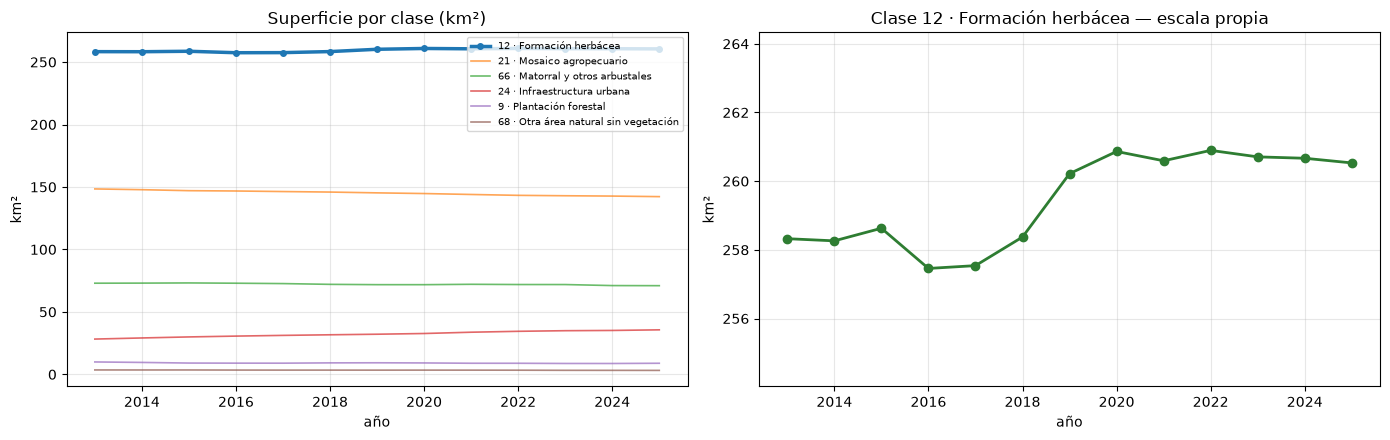


Variación de la clase 12 en el periodo: 258.3 → 260.5 km² (+0.9 %)
MapBiomas la reporta prácticamente estable. Ese es el punto: su clasificación anual no
ve degradación DENTRO de la clase, solo el cambio DE clase. Ahí entra este proyecto.


In [5]:
# Composición del año base, con el peso de cada clase
base = (areas[areas["anio"] == ANIO_INI]
        .sort_values("km2", ascending=False)
        .assign(pct=lambda d: d["km2"] / d["km2"].sum() * 100))

print(f"COMPOSICIÓN DE LA PROVINCIA EN {ANIO_INI}")
print("=" * 62)
for _, f in base.iterrows():
    marca = "  <<< OBJETIVO" if f["clase"] == CLASE_OBJETIVO else ""
    print(f"  {f['clase']:3d} · {f['nombre']:38s} {f['km2']:7.2f} km²  {f['pct']:5.2f} %{marca}")
print("=" * 62)
print(f"  {'TOTAL':44s} {base['km2'].sum():7.2f} km²")

# Evolución de las clases principales
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

principales = base.head(6)["clase"].tolist()
for c in principales:
    serie = areas[(areas["clase"] == c) & (areas["anio"] >= ANIO_INI)].sort_values("anio")
    estilo = dict(lw=2.5, marker="o", ms=4) if c == CLASE_OBJETIVO else dict(lw=1.2, alpha=0.7)
    ejes[0].plot(serie["anio"], serie["km2"], label=f"{c} · {NOMBRES.get(c, c)}", **estilo)
ejes[0].set_title("Superficie por clase (km²)")
ejes[0].set_ylabel("km²")
ejes[0].legend(fontsize=7)

# La clase objetivo sola, con su propia escala: así se ve que MapBiomas la reporta estable
obj = areas[(areas["clase"] == CLASE_OBJETIVO) & (areas["anio"] >= ANIO_INI)].sort_values("anio")
ejes[1].plot(obj["anio"], obj["km2"], "o-", color="#2e7d32", lw=2)
ejes[1].set_title(f"Clase {CLASE_OBJETIVO} · {NOMBRES[CLASE_OBJETIVO]} — escala propia")
ejes[1].set_ylabel("km²")
rango = obj["km2"].max() - obj["km2"].min()
ejes[1].set_ylim(obj["km2"].min() - rango, obj["km2"].max() + rango)

for e in ejes:
    e.set_xlabel("año")
    e.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nVariación de la clase {CLASE_OBJETIVO} en el periodo: "
      f"{obj['km2'].iloc[0]:.1f} → {obj['km2'].iloc[-1]:.1f} km² "
      f"({(obj['km2'].iloc[-1] / obj['km2'].iloc[0] - 1) * 100:+.1f} %)")
print("MapBiomas la reporta prácticamente estable. Ese es el punto: su clasificación anual no")
print("ve degradación DENTRO de la clase, solo el cambio DE clase. Ahí entra este proyecto.")

## 6 · La máscara de pastizal

Hay que decidir qué píxeles cuentan como pastizal, y la decisión no es obvia porque la clase de un
píxel puede cambiar durante el periodo. Tres definiciones posibles, cada una responde a una
pregunta distinta:

| Modo | Definición | Pregunta que responde | Riesgo |
|---|---|---|---|
| `base` | Clase 12 en el año inicial | ¿Qué le pasó al pajonal que había en 2013? | Incluye píxeles que después pasaron legítimamente a otra clase (urbano, agrícola) |
| `union` | Clase 12 en al menos un año | ¿Dónde hubo pajonal alguna vez? | Muy permisiva: un solo año mal clasificado mete el píxel |
| `estable` | Clase 12 en **todos** los años | ¿Qué le pasó al pajonal que siguió siendo pajonal? | Más restrictiva: deja fuera píxeles que sí eran pajonal pero MapBiomas clasificó distinto algún año |

**Se usa `estable`**, y la razón es el objeto de estudio. Buscamos **degradación intraclase**: el
pajonal que MapBiomas sigue llamando pajonal pero que por dentro está perdiendo cobertura. Si un
píxel cambió de clase, ese cambio ya lo detectó MapBiomas y no es lo que aportamos nosotros — lo
reportamos como transición en la sección 7, pero no es degradación intraclase.

Dicho de otro modo: `estable` aísla exactamente la población donde MapBiomas dice "aquí no pasó
nada" y nosotros podemos decir si pasó algo.

El costo es que la máscara depende de la calidad de MapBiomas en el bioma Andes, que es donde menos
muestras de entrenamiento tiene (sección 2). Por eso las tres definiciones quedan calculadas: si la
estable resulta demasiado restrictiva, cambiar `MASCARA_MODO` y volver a ejecutar es inmediato.

In [6]:
def mascara_clase(codigo, modo="estable", anios=None):
    """Máscara booleana de una clase de MapBiomas según el modo temporal elegido."""
    anios = anios or ANIOS
    # rename("m") es necesario: cada banda se llama classification_YYYY y los reductores de
    # ImageCollection exigen que todas las imágenes compartan el nombre de banda.
    capas = [mb.select(f"classification_{a}").eq(codigo).rename("m") for a in anios]
    pila = ee.ImageCollection(capas)
    if modo == "estable":
        return pila.min().rename("mascara")        # en TODOS los años
    if modo == "union":
        return pila.max().rename("mascara")        # en AL MENOS UNO
    if modo == "base":
        return capas[0].rename("mascara")          # en el año inicial
    raise ValueError(f"modo no reconocido: {modo}")


def km2_de(mascara):
    """Superficie en km² de una máscara booleana dentro de la provincia."""
    v = (ee.Image.pixelArea().divide(1e6).updateMask(mascara)
         .reduceRegion(ee.Reducer.sum(), aoi, ESCALA, maxPixels=1e10, bestEffort=True))
    return ee.Number(v.get("area"))


# Las tres definiciones, para poder comparar antes de fijar la decisión
modos = ["base", "union", "estable"]
print("Superficie de la clase objetivo según cada definición:")
km2_modos = evaluar_serie([km2_de(mascara_clase(CLASE_OBJETIVO, m)) for m in modos], modos)

comparacion = pd.DataFrame({
    "modo": modos,
    "km2": [round(v, 2) for v in km2_modos],
})
comparacion["% de la provincia"] = (comparacion["km2"] / area_km2 * 100).round(1)
comparacion["píxeles"] = (comparacion["km2"] * 1e6 / ESCALA**2).astype(int)
comparacion["elegido"] = np.where(comparacion["modo"] == MASCARA_MODO, "<<<", "")
display(comparacion.set_index("modo"))

pastizal = mascara_clase(CLASE_OBJETIVO, MASCARA_MODO).selfMask()
n_pix = int(comparacion.loc[comparacion["modo"] == MASCARA_MODO, "píxeles"].iloc[0])
print(f"\nMáscara en uso: '{MASCARA_MODO}' → {n_pix:,} píxeles de pastizal")
print(f"Con unidad mínima de mapeo de 1 ha (11 píxeles), caben ~{n_pix // 11:,} parches mínimos.")
print("Población más que suficiente para muestreo estratificado y estimación de área.")

Superficie de la clase objetivo según cada definición:
  [1/3] base  ok
  [2/3] union  ok
  [3/3] estable  ok


,km2,% de la provincia,píxeles,elegido
modo,,,,
base,258.33,48.7,287033,
union,266.47,50.3,296077,
estable,251.86,47.5,279844,<<<



Máscara en uso: 'estable' → 279,844 píxeles de pastizal
Con unidad mínima de mapeo de 1 ha (11 píxeles), caben ~25,440 parches mínimos.
Población más que suficiente para muestreo estratificado y estimación de área.


## 7 · Estratos de exclusión

No todo lo que está dentro de la máscara de pastizal es interpretable como degradación de pajonal.
Cuatro grupos se separan, cada uno por un motivo distinto:

- **Bofedales (clases 11, 82 y 51).** Son humedales altoandinos. Su dinámica depende del agua y de
  la nieve, no del pastoreo, y responde a la precipitación acumulada de hasta dos años previos
  (Chávez et al. 2019, *Remote Sensing* 11(24):2955). Una caída de verdor en un bofedal puede ser
  una sequía y no degradación. MapBiomas tiene clase propia para el bofedal altoandino (**82**), así
  que no hay que inventar la delimitación. Se analizan aparte, nunca dentro del indicador principal.
- **Glaciar (34) y agua (33, 31).** Superficies sin vegetación cuya variación no tiene nada que ver
  con el pajonal. El glaciar además cambia de extensión entre años, lo que genera falsos quiebres en
  el borde.
- **Superficie rocosa (92).** Es el destino posible de un pajonal que pierde toda su cobertura. Se
  excluye del universo de medición pero **sí interesa como transición**: pajonal → roca es el caso
  extremo de degradación.
- **El borde entre coberturas.** Un píxel en la frontera entre dos clases mezcla la señal de ambas y
  produce quiebres espurios. Se erosiona la máscara un píxel para quitarlos.

El resultado es la **máscara de análisis**: el universo donde el indicador de degradación es
interpretable.

In [7]:
# Unión de todo lo que se excluye (en cualquier año del periodo)
capas_excluir = []
for codigo in CLASES_EXCLUIR:
    capas_excluir.append(mascara_clase(codigo, "union"))
excluir = ee.ImageCollection(capas_excluir).max().rename("excluir")

# Borde: píxeles donde la máscara de pastizal toca otra cobertura.
# focal_min con un kernel de 1 píxel erosiona el contorno.
pastizal_bin = mascara_clase(CLASE_OBJETIVO, MASCARA_MODO).unmask(0)
sin_borde = pastizal_bin.focal_min(radius=1, units="pixels")

mascara_analisis = pastizal_bin.And(excluir.unmask(0).Not()).And(sin_borde).selfMask()

# Cuánto quita cada filtro
print("Efecto de cada filtro sobre la máscara:")
pasos = evaluar_serie(
    [km2_de(pastizal_bin.selfMask()),
     km2_de(pastizal_bin.And(excluir.unmask(0).Not()).selfMask()),
     km2_de(mascara_analisis)],
    ["clase 12", "menos exclusiones", "menos borde"])

resumen_mascara = pd.DataFrame({
    "paso": ["pastizal (clase 12)", "menos exclusiones", "menos borde = MÁSCARA DE ANÁLISIS"],
    "km2": [round(v, 2) for v in pasos],
})
resumen_mascara["píxeles"] = (resumen_mascara["km2"] * 1e6 / ESCALA**2).astype(int)
resumen_mascara["pierde"] = resumen_mascara["km2"].diff().fillna(0).round(2)
display(resumen_mascara.set_index("paso"))

# Superficie de cada estrato excluido, por si hace falta analizarlo aparte
print("\nSuperficie de cada estrato excluido:")
est = evaluar_serie([km2_de(mascara_clase(c, "union").selfMask()) for c in CLASES_EXCLUIR],
                    [f"{c} · {n}" for c, n in CLASES_EXCLUIR.items()])
estratos = pd.DataFrame({
    "clase": list(CLASES_EXCLUIR.keys()),
    "nombre": list(CLASES_EXCLUIR.values()),
    "km2": [round(v, 2) for v in est],
}).sort_values("km2", ascending=False)
print("\nEstratos excluidos (superficie en cualquier año del periodo):")
display(estratos[estratos["km2"] > 0].set_index("clase"))

bofedal = estratos[estratos["clase"].isin([11, 82, 51])]["km2"].sum()
if bofedal > 0:
    print(f"Bofedales (clases 11, 82, 51): {bofedal:.2f} km². Se analizan aparte,")
    print("nunca dentro del indicador principal de degradación de pajonal.")

Efecto de cada filtro sobre la máscara:
  [1/3] clase 12  ok
  [2/3] menos exclusiones  ok
  [3/3] menos borde  ok


,km2,píxeles,pierde
paso,,,
pastizal (clase 12),251.86,279844,0.00
menos exclusiones,251.86,279844,0.00
menos borde = MÁSCARA DE ANÁLISIS,219.03,243366,-32.83



Superficie de cada estrato excluido:
  [1/7] 11 · Formación herbácea inundable  ok
  [2/7] 82 · Herbazal inundable altoandino  ok
  [3/7] 51 · Herbazal inundable de tierras bajas  ok
  [4/7] 33 · Río, lago u océano  ok
  [5/7] 31 · Acuicultura  ok
  [6/7] 34 · Glaciar  ok
  [7/7] 92 · Superficie rocosa  ok

Estratos excluidos (superficie en cualquier año del periodo):


,nombre,km2
clase,,
82,Herbazal inundable altoandino,4.33
33,"Río, lago u océano",0.88
92,Superficie rocosa,0.05


Bofedales (clases 11, 82, 51): 4.33 km². Se analizan aparte,
nunca dentro del indicador principal de degradación de pajonal.


## 8 · Matriz de transiciones

Qué clase pasó a qué clase, **a nivel de clase de MapBiomas y sin agrupar**. Estos son los
indicadores de referencia contra los que se contrasta el resultado propio en el paso 8 de la
metodología.

Las transiciones que interesan para el pastizal:

- **12 → 21** (mosaico agropecuario): conversión a uso agrícola
- **12 → 24** (infraestructura urbana): expansión urbana sobre pajonal
- **12 → 92** (superficie rocosa): pérdida total de cobertura, el caso extremo de degradación
- **12 → 66** (matorral): arbustización, que es un cambio distinto a la degradación y conviene no
  confundir
- **12 → 15** (pasto sembrado): conversión de pajonal natural a pasto manejado
- **21 → 12** y **66 → 12**: recuperación o abandono

La técnica para construirla es codificar el par de clases en un solo número: `origen × 100 + destino`
funciona porque el código más alto de la leyenda es 92, menor que 100.

Eso permite sacar **toda** la matriz de un periodo con **una sola agregación**, y después derivar
cada indicador con pandas sin volver a consultar. La alternativa —una reducción por indicador—
daría 7 × 12 = 84 consultas, que es justo lo que dispara el límite de agregaciones concurrentes.
Con este enfoque son 13 en total y se evalúan en serie.

In [8]:
def matriz_transicion(anio_a, anio_b):
    """Todas las transiciones de clase entre dos años, en UNA sola agregación.

    Codifica el par origen→destino como un número (origen*100 + destino) y agrupa por él.
    Es seguro porque el código más alto de la leyenda es 92, menor que 100.

    Una agregación por periodo en vez de una por indicador: con 7 indicadores y 12 periodos
    serían 84 reducciones, que es justo lo que dispara 'Too many concurrent aggregations'.
    """
    ca = mb.select(f"classification_{anio_a}")
    cb = mb.select(f"classification_{anio_b}")
    par = ca.multiply(100).add(cb).rename("par")
    grupos = (ee.Image.pixelArea().divide(1e6).rename("km2").addBands(par)
              .reduceRegion(
                  reducer=ee.Reducer.sum().group(groupField=1, groupName="par"),
                  geometry=aoi, scale=ESCALA, maxPixels=1e10, bestEffort=True))
    return grupos.get("groups")


def a_dataframe(grupos, anio_a, anio_b):
    """Convierte la salida agrupada en filas origen / destino / km2."""
    filas = []
    for g in grupos:
        par = int(g["par"])
        o, d = par // 100, par % 100
        filas.append({"periodo": f"{anio_a}→{anio_b}", "origen": o, "destino": d,
                      "de": NOMBRES.get(o, f"clase {o}"), "a": NOMBRES.get(d, f"clase {d}"),
                      "km2": g["sum"]})
    return pd.DataFrame(filas)


# Una agregación por periodo: el total y cada par de años consecutivos
pares = [(ANIO_INI, ANIO_FIN)] + list(zip(ANIOS[:-1], ANIOS[1:]))
print(f"Matrices de transición de {len(pares)} periodos (en serie):")
brutos = evaluar_serie([matriz_transicion(a, b) for a, b in pares],
                       [f"{a}→{b}" for a, b in pares])

matrices = pd.concat([a_dataframe(g, a, b) for g, (a, b) in zip(brutos, pares)],
                     ignore_index=True)
matrices.to_csv(SALIDA / "matrices_transicion.csv", index=False)
print("\nGuardado en", SALIDA / "matrices_transicion.csv")

# Periodo completo, visto desde el pastizal
total = matrices[matrices["periodo"] == f"{ANIO_INI}→{ANIO_FIN}"]
desde_obj = total[total["origen"] == CLASE_OBJETIVO]
permanece = desde_obj[desde_obj["destino"] == CLASE_OBJETIVO]["km2"].sum()
cambia = desde_obj[desde_obj["destino"] != CLASE_OBJETIVO]["km2"].sum()

print(f"\nPASTIZAL (clase {CLASE_OBJETIVO}) · {ANIO_INI} → {ANIO_FIN}")
print("=" * 66)
print(f"  Permanece como pastizal : {permanece:8.2f} km²  "
      f"({permanece / (permanece + cambia) * 100:.2f} %)")
print(f"  Cambia de clase         : {cambia:8.2f} km²  "
      f"({cambia / (permanece + cambia) * 100:.2f} %)")
print("=" * 66)
print("\nDestinos del pajonal que sí cambió de clase:")
display(desde_obj[desde_obj["destino"] != CLASE_OBJETIVO]
        .sort_values("km2", ascending=False)
        .assign(km2=lambda d: d["km2"].round(3))[["destino", "a", "km2"]]
        .set_index("destino"))

print(f"El {permanece / (permanece + cambia) * 100:.1f} % del pajonal sigue siendo pajonal "
      "para MapBiomas.")
print("Sobre ESA superficie es donde nuestro indicador puede decir algo que MapBiomas no dice.")

Matrices de transición de 13 periodos (en serie):
  [1/13] 2013→2025  

ok
  [2/13] 2013→2014  ok
  [3/13] 2014→2015  ok
  [4/13] 2015→2016  ok
  [5/13] 2016→2017  ok
  [6/13] 2017→2018  ok
  [7/13] 2018→2019  ok
  [8/13] 2019→2020  ok
  [9/13] 2020→2021  ok
  [10/13] 2021→2022  ok
  [11/13] 2022→2023  ok
  [12/13] 2023→2024  ok
  [13/13] 2024→2025  ok

Guardado en F:\Cobertura de suelo\outputs\02_referencia_cobertura\matrices_transicion.csv

PASTIZAL (clase 12) · 2013 → 2025
  Permanece como pastizal :   254.92 km²  (98.68 %)
  Cambia de clase         :     3.40 km²  (1.32 %)

Destinos del pajonal que sí cambió de clase:


,a,km2
destino,,
15,Pasto (beta),1.646
21,Mosaico agropecuario,0.923
30,Minería,0.211
66,Matorral y otros arbustales,0.204
82,Herbazal inundable altoandino,0.198
24,Infraestructura urbana,0.107
9,Plantación forestal,0.054
3,Bosque,0.026
68,Otra área natural sin vegetación,0.018


El 98.7 % del pajonal sigue siendo pajonal para MapBiomas.
Sobre ESA superficie es donde nuestro indicador puede decir algo que MapBiomas no dice.


In [9]:
# Indicadores de referencia año a año, derivados de las matrices ya calculadas.
# No hace falta ninguna consulta nueva: todo sale de 'matrices' con pandas.
BOSQUE = set(CLASES_BOSQUE)


def indicadores_de(m):
    """Indicadores de referencia de un periodo, a partir de su matriz de transición."""
    o, d, km2 = m["origen"], m["destino"], m["km2"]
    es_obj_o, es_obj_d = o == CLASE_OBJETIVO, d == CLASE_OBJETIVO
    bos_o, bos_d = o.isin(BOSQUE), d.isin(BOSQUE)
    return {
        "pastizal_pierde": km2[es_obj_o & ~es_obj_d].sum(),
        "pastizal_gana": km2[~es_obj_o & es_obj_d].sum(),
        "pastizal_a_agricola": km2[es_obj_o & (d == 21)].sum(),
        "pastizal_a_urbano": km2[es_obj_o & (d == 24)].sum(),
        "pastizal_a_roca": km2[es_obj_o & (d == 92)].sum(),
        "pastizal_a_matorral": km2[es_obj_o & (d == 66)].sum(),
        "pastizal_a_pasto_sembrado": km2[es_obj_o & (d == 15)].sum(),
        "bosque_pierde": km2[bos_o & ~bos_d].sum(),
        "bosque_gana": km2[~bos_o & bos_d].sum(),
    }


consecutivos = [f"{a}→{b}" for a, b in zip(ANIOS[:-1], ANIOS[1:])]
ind = pd.DataFrame(
    [{"periodo": p, **indicadores_de(matrices[matrices["periodo"] == p])}
     for p in consecutivos]
).round(3)

ind.to_csv(SALIDA / "indicadores_referencia.csv", index=False)
display(ind.set_index("periodo"))
print("Guardado en", SALIDA / "indicadores_referencia.csv")

print(f"\nTotales del periodo {ANIO_INI}–{ANIO_FIN} (suma de los cambios anuales):")
for c in ind.columns:
    if c != "periodo":
        print(f"  {c:28s} {ind[c].sum():7.2f} km²")

print("\nNota sobre 'bosque_pierde' y 'bosque_gana': agrupan las 4 clases del grupo nivel 1")
print("'Formación boscosa' (3, 4, 5, 6). Es el ÚNICO lugar donde se agrupa, y solo porque")
print("el grupo es el oficial de MapBiomas y el bosque es indicador secundario.")
print("Ver docs/00_proyecto.md §2: con ~2 km² de bosque en la provincia, estas cifras no")
print("soportan una estimación de área con intervalos de confianza.")

,pastizal_pierde,pastizal_gana,pastizal_a_agricola,pastizal_a_urbano,pastizal_a_roca,pastizal_a_matorral,pastizal_a_pasto_sembrado,bosque_pierde,bosque_gana
periodo,,,,,,,,,
2013→2014,0.921,0.858,0.284,0.000,0.000,0.087,0.312,0.075,0.060
2014→2015,1.082,1.449,0.212,0.011,0.000,0.060,0.688,0.072,0.021
2015→2016,1.875,0.705,0.417,0.016,0.004,0.137,1.047,0.054,0.073
2016→2017,0.752,0.834,0.126,0.001,0.000,0.097,0.402,0.070,0.019
2017→2018,0.621,1.454,0.240,0.001,0.000,0.110,0.195,0.077,0.031
2018→2019,0.459,2.304,0.117,0.012,0.000,0.149,0.076,0.056,0.055
2019→2020,0.622,1.268,0.197,0.002,0.000,0.149,0.116,0.105,0.015
2020→2021,0.880,0.608,0.191,0.004,0.000,0.328,0.209,0.028,0.064
2021→2022,0.590,0.892,0.264,0.001,0.000,0.100,0.143,0.035,0.029


Guardado en F:\Cobertura de suelo\outputs\02_referencia_cobertura\indicadores_referencia.csv

Totales del periodo 2013–2025 (suma de los cambios anuales):
  pastizal_pierde                10.91 km²
  pastizal_gana                  13.12 km²
  pastizal_a_agricola             2.63 km²
  pastizal_a_urbano               0.10 km²
  pastizal_a_roca                 0.00 km²
  pastizal_a_matorral             1.52 km²
  pastizal_a_pasto_sembrado       4.82 km²
  bosque_pierde                   0.70 km²
  bosque_gana                     0.51 km²

Nota sobre 'bosque_pierde' y 'bosque_gana': agrupan las 4 clases del grupo nivel 1
'Formación boscosa' (3, 4, 5, 6). Es el ÚNICO lugar donde se agrupa, y solo porque
el grupo es el oficial de MapBiomas y el bosque es indicador secundario.
Ver docs/00_proyecto.md §2: con ~2 km² de bosque en la provincia, estas cifras no
soportan una estimación de área con intervalos de confianza.


## 9 · Control visual

Dos mapas: la clase del año base sobre la provincia, y la máscara de análisis resultante. Sirve para
verificar que el pajonal está donde se espera (laderas y zonas altas), que la ciudad de Cusco quedó
fuera, y que las exclusiones no dejaron la máscara con agujeros raros.

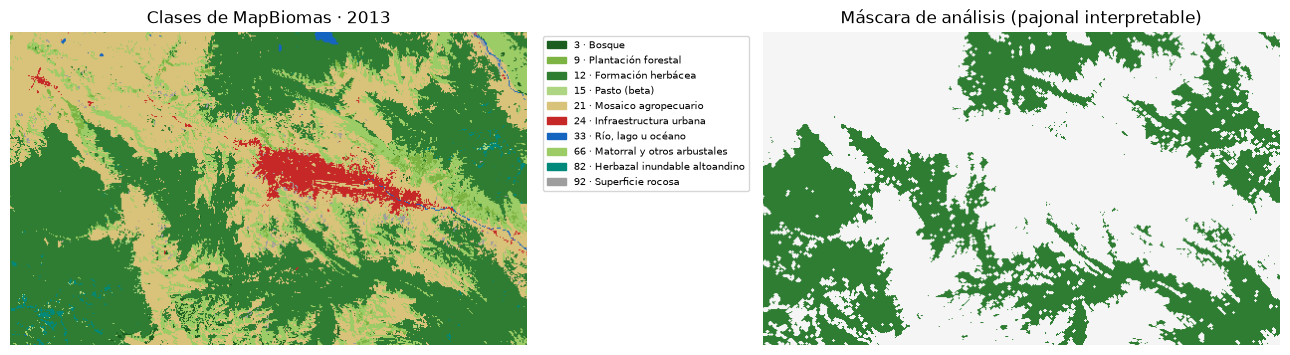

Qué verificar:
  · El pajonal (verde oscuro) debería estar en laderas y zonas altas
  · La ciudad de Cusco (rojo) debe quedar FUERA de la máscara de análisis
  · La máscara no debería tener agujeros grandes inexplicables


In [10]:
def miniatura(img, vis, ancho=520):
    """Miniatura PNG de una imagen recortada a la provincia."""
    from PIL import Image
    import requests, io
    url = img.getThumbURL({**vis, "region": aoi, "dimensions": ancho, "format": "png"})
    return np.array(Image.open(io.BytesIO(requests.get(url, timeout=180).content)))


# Paleta: objetivo en verde, agropecuario en ocre, urbano en rojo, agua en azul, resto en gris
paleta = {CLASE_OBJETIVO: "2e7d32", 21: "d9c27a", 24: "c62828", 9: "7cb342",
          66: "9ccc65", 15: "aed581", 33: "1565c0", 34: "b3e5fc", 92: "9e9e9e",
          3: "1b5e20", 82: "00897b", 11: "4db6ac"}
codigos_vis = sorted(c for c in presentes if c in paleta)
clases_img = (mb.select(f"classification_{ANIO_INI}")
                .remap(codigos_vis, list(range(len(codigos_vis))), 999))

fig, ejes = plt.subplots(1, 2, figsize=(13, 6.5))
ejes[0].imshow(miniatura(clases_img, {
    "min": 0, "max": len(codigos_vis) - 1,
    "palette": [paleta[c] for c in codigos_vis]}))
ejes[0].set_title(f"Clases de MapBiomas · {ANIO_INI}")

ejes[1].imshow(miniatura(mascara_analisis.unmask(0), {
    "min": 0, "max": 1, "palette": ["f5f5f5", "2e7d32"]}))
ejes[1].set_title("Máscara de análisis (pajonal interpretable)")

for e in ejes:
    e.axis("off")

import matplotlib.patches as mpatches
ejes[0].legend(handles=[mpatches.Patch(color=f"#{paleta[c]}",
                                       label=f"{c} · {NOMBRES.get(c, c)}")
                        for c in codigos_vis],
               loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=7)
plt.tight_layout()
plt.show()

print("Qué verificar:")
print("  · El pajonal (verde oscuro) debería estar en laderas y zonas altas")
print("  · La ciudad de Cusco (rojo) debe quedar FUERA de la máscara de análisis")
print("  · La máscara no debería tener agujeros grandes inexplicables")

## 10 · Exportar las máscaras

La máscara de pajonal y la de análisis son el producto principal de este notebook: definen **dónde**
se mide degradación, y todo lo que sigue depende de ellas.

Hasta esta versión no se exportaban, así que el notebook de detección las reconstruía desde
MapBiomas con su propia copia de `mascara_clase()`. Eran dos definiciones separadas de lo mismo: si
se cambiaba `MASCARA_MODO` aquí y no allá, los dos notebooks medían sobre poblaciones distintas sin
avisar de nada. Es el mismo riesgo que ya tuvimos con las funciones de compuesto duplicadas.

Ahora se exportan una vez y el resto las lee.

### Qué lleva el asset

Dos bandas de 8 bits, más los metadatos que explican cómo se construyeron:

| Banda | Contenido |
|---|---|
| `pastizal` | Clase 12 según el modo elegido (`MASCARA_MODO`) |
| `analisis` | `pastizal` menos las clases excluidas y menos el borde erosionado |

Los metadatos guardan el modo de máscara, la clase objetivo, las clases excluidas y el periodo. Sin
eso, dentro de seis meses nadie sabría si el asset se hizo con la máscara `estable`, `union` o
`base`, y las tres dan superficies distintas.

In [ ]:
ASSET_MASCARA = f"projects/{GEE_PROJECT}/assets/cusco_02_mascara"
EXPORTAR_MASCARA = False       # ponlo en True una sola vez

mascaras = (pastizal.unmask(0).rename("pastizal")
            .addBands(mascara_analisis.unmask(0).rename("analisis"))
            .toByte()
            .set({
                "mascara_modo": MASCARA_MODO,
                "clase_objetivo": CLASE_OBJETIVO,
                "clases_excluidas": ",".join(str(c) for c in CLASES_EXCLUIR),
                "anio_ini": ANIO_INI,
                "anio_fin": ANIO_FIN,
                "fuente": MB_ASSET.split("/")[-1],
                "notebook": "02_referencia_cobertura",
            }))

print("Bandas del asset:", mascaras.bandNames().getInfo())
print("Modo de máscara :", MASCARA_MODO)
print("Clase objetivo  :", CLASE_OBJETIVO, "·", NOMBRES[CLASE_OBJETIVO])
print("Clases excluidas:", list(CLASES_EXCLUIR))

if EXPORTAR_MASCARA:
    tarea = ee.batch.Export.image.toAsset(
        image=mascaras, description="cusco_02_mascara", assetId=ASSET_MASCARA,
        region=aoi, scale=ESCALA, crs=GRID_CRS, maxPixels=1e10,
        pyramidingPolicy={".default": "mode"})     # mode, no mean: son máscaras binarias
    tarea.start()
    print("\nTarea lanzada:", tarea.id, "→", ASSET_MASCARA)
    print("Seguimiento: pestaña Tasks del Code Editor, o ee.batch.Task.list()")
else:
    print("\nEXPORTAR_MASCARA = False.")
    print("Ponlo en True y ejecuta esta celda UNA VEZ para crear", ASSET_MASCARA)
    print("El notebook 05 lee las máscaras de ese asset en vez de reconstruirlas.")

Bandas del asset: ['pastizal', 'analisis']
Modo de máscara : estable
Clase objetivo  : 12 · Formación herbácea
Clases excluidas: [11, 82, 51, 33, 31, 34, 92]

Tarea lanzada: PCOGMFP7MFSEOV4NLWXBEBSO → projects/viirs-peru/assets/cusco_02_mascara
Seguimiento: pestaña Tasks del Code Editor, o ee.batch.Task.list()


## 10 · Resumen

In [12]:
km2_analisis = resumen_mascara["km2"].iloc[-1]
pix_analisis = int(resumen_mascara["píxeles"].iloc[-1])
obj_base = float(base.loc[base["clase"] == CLASE_OBJETIVO, "km2"].iloc[0])
obj_pct = float(base.loc[base["clase"] == CLASE_OBJETIVO, "pct"].iloc[0])

print("=" * 76)
print("RESUMEN · notebook 02 · MapBiomas como referencia temática")
print("=" * 76)
print(f"Fuente     : MapBiomas Perú Colección 4 · bioma Andes")
print(f"Área       : provincia de Cusco, {area_km2:,.1f} km² (límite INEI)")
print(f"Periodo    : {ANIOS[0]}–{ANIOS[-1]} ({len(ANIOS)} años)"
      f" + {ANIOS_CONTEXTO} solo como contexto")
print()
print(f"CLASE OBJETIVO · {CLASE_OBJETIVO} · {NOMBRES[CLASE_OBJETIVO]} (pajonal andino)")
print(f"  Superficie en {ANIO_INI}        : {obj_base:.1f} km²  ({obj_pct:.1f} % de la provincia)")
print(f"  Variación {ANIO_INI}–{ANIO_FIN}      : {obj['km2'].iloc[0]:.1f} → {obj['km2'].iloc[-1]:.1f} km²"
      f"  ({(obj['km2'].iloc[-1]/obj['km2'].iloc[0]-1)*100:+.1f} %) — MapBiomas la ve estable")
print()
print(f"MÁSCARA DE ANÁLISIS (modo '{MASCARA_MODO}')")
print(f"  Superficie               : {km2_analisis:.1f} km²")
print(f"  Píxeles                  : {pix_analisis:,}")
print(f"  Parches de 1 ha posibles : ~{pix_analisis // 11:,}")
print()
print("EXCLUIDOS (estratos aparte, no entran al indicador principal)")
for _, f in estratos[estratos["km2"] > 0].iterrows():
    print(f"  {int(f['clase']):3d} · {f['nombre']:38s} {f['km2']:7.2f} km²")
print()
print("ARCHIVOS GENERADOS")
for n in ["areas_por_clase.csv", f"transiciones_pastizal_{ANIO_INI}_{ANIO_FIN}.csv",
          "indicadores_referencia.csv"]:
    print("  ", SALIDA / n)
print()
print("-" * 76)
print("LÍMITES DE ESTA FUENTE — declarar en todo entregable que la use")
print("-" * 76)
print("· MapBiomas es un Random Forest, no verdad de campo. En el bioma Andes se entrenó")
print("  con 20–100 muestras estables por región, frente a 500–3000 en la Amazonía.")
print("· Clasifica cada año de forma independiente, así que su 'cambio' arrastra el error")
print("  de clasificación de los dos años comparados.")
print("· Su propio apéndice técnico reconoce que el pajonal andino 'se confunde con suelo")
print("  desnudo (pasto seco)' — la misma confusión que motiva usar -TCW y no NDVI.")
print("· Se usa para DELIMITAR y CONTRASTAR, nunca para VALIDAR. La validación va con")
print("  muestreo estratificado e interpretación visual (paso 6).")
print()
print("SIGUIENTE · notebook 03 (ya ejecutado) y notebook 04 · LandTrendr")
print("  La máscara de análisis de este notebook acota dónde se interpreta el resultado")
print("  de LandTrendr. El indicador de degradación se calcula solo ahí.")
print("=" * 76)

RESUMEN · notebook 02 · MapBiomas como referencia temática
Fuente     : MapBiomas Perú Colección 4 · bioma Andes
Área       : provincia de Cusco, 530.1 km² (límite INEI)
Periodo    : 2013–2025 (13 años) + [2005, 2010] solo como contexto

CLASE OBJETIVO · 12 · Formación herbácea (pajonal andino)
  Superficie en 2013        : 258.3 km²  (48.8 % de la provincia)
  Variación 2013–2025      : 258.3 → 260.5 km²  (+0.9 %) — MapBiomas la ve estable

MÁSCARA DE ANÁLISIS (modo 'estable')
  Superficie               : 219.0 km²
  Píxeles                  : 243,366
  Parches de 1 ha posibles : ~22,124

EXCLUIDOS (estratos aparte, no entran al indicador principal)
   82 · Herbazal inundable altoandino             4.33 km²
   33 · Río, lago u océano                        0.88 km²
   92 · Superficie rocosa                         0.05 km²

ARCHIVOS GENERADOS
   F:\Cobertura de suelo\outputs\02_referencia_cobertura\areas_por_clase.csv
   F:\Cobertura de suelo\outputs\02_referencia_cobertura\transicion

## Por si queremos ver las 2 máscaras

In [14]:
mascaras = ee.Image("projects/viirs-peru/assets/cusco_02_mascara")
pastizal = mascaras.select("pastizal")   # máscara 1
analisis = mascaras.select("analisis")   # máscara 2

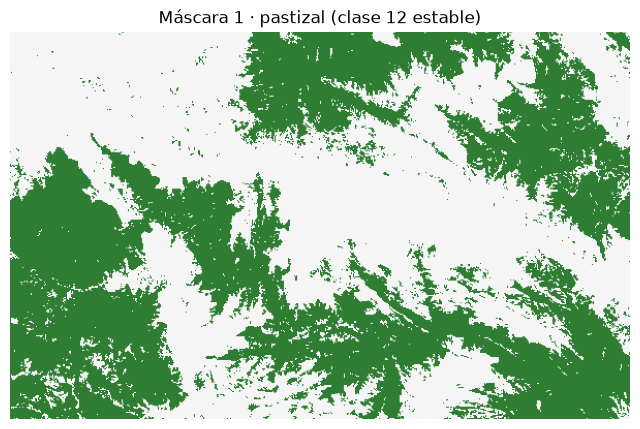

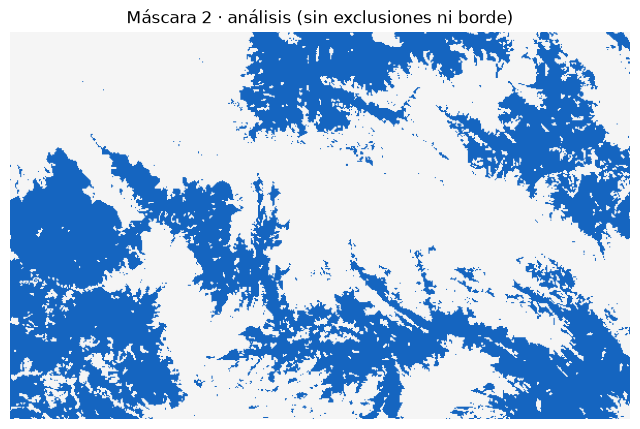

In [17]:
import requests
import io
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# El polígono de la provincia para recortar la vista
aoi_fc = ee.FeatureCollection("projects/viirs-peru/assets/cusco_01_aoi")
aoi = aoi_fc.geometry()

def ver(img, titulo, color_1="2e7d32"):
    """Descarga una miniatura PNG de la imagen y la muestra."""
    url = img.unmask(0).getThumbURL({
        "region": aoi,
        "dimensions": 600,
        "format": "png",
        "min": 0,
        "max": 1,
        "palette": ["f5f5f5", color_1],   # fondo claro, pajonal verde
    })
    arr = np.array(Image.open(io.BytesIO(requests.get(url, timeout=180).content)))
    plt.figure(figsize=(8, 6))
    plt.imshow(arr)
    plt.title(titulo)
    plt.axis("off")
    plt.show()

ver(pastizal, "Máscara 1 · pastizal (clase 12 estable)")
ver(analisis, "Máscara 2 · análisis (sin exclusiones ni borde)", color_1="1565c0")